# NOTEBOOK 07: SUPERVISED MACHINE LEARNING & COMPETENCY LAB (B0 — B3)
## Core Strategy & Intelligence Platform (CSIP) — Modul MVP: BDI
**Standar Metodologi Data Science**:
- `[UK-08 Membangun Skenario Model]` (Skenario E0-E6 & Baseline Ladder B0-B3)
- `[UK-09 Membangun Model]` (Supervised Learning: Regresi, Klasifikasi, Tree, KNN, Naive Bayes, LightGBM)
- `[UK-10 Mengevaluasi Hasil Pemodelan]` (Evaluasi PR-AUC, ROC-AUC, Brier Score, & MAE/RMSE)

---

### 1. Desain Eksperimen & Baseline Ladder (B0 — B3)
Setiap tugas pemodelan diuji melalui tangga pembanding model (*Baseline Ladder*) untuk membuktikan bahwa kompleksitas model benar-benar terjustifikasi:
- **B0 — Naive Baseline**: Majority Class Classifier & Mean Regressor.
- **B1 — Statistical Baseline**: Logistic Regression (balanced) & Ridge Regression.
- **B2 — Classical Benchmarks (Competency Lab)**: Decision Tree, K-Nearest Neighbors (KNN), Gaussian Naive Bayes.
- **B3 — Ensemble Trees**: Random Forest & LightGBM.
- **Evaluasi Temporal Orders**: Train s/d Maret 2018 (64,156), Val April–Juni 2018 (19,684), Test Juli–Agustus 2018 (12,630).
- **Evaluasi Cohort Embargo (Finding F-02 / P-02)**: Train s/d 31 Agu 2017 (21,664), Embargo 91d, Val Des 2017–Jan 2018 (12,180), Embargo 89d, Test Mei 2018 (6,439).
- **Estimand E1 (`E1_checkout_retrospective_conditional`)**: $\mathbb{P}(\text{Negative Review} = 1 \mid X_{t_0}, \text{Delivered} = 1, \text{Review Observed} = 1)$ (Risiko retrospektif bersyarat pemenuhan pesanan).


In [1]:
import sys
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

# Load Leaderboard Hasil Pelatihan Model
with open(PROJECT_ROOT / "artifacts" / "reports" / "ml_leaderboard.json", "r") as f:
    leaderboard_data = json.load(f)

leaderboard_df = pd.DataFrame(leaderboard_data)
print(f"Total Eksperimen Terlatih: {len(leaderboard_df)} skenario")


Total Eksperimen Terlatih: 36 skenario


### 2. Papan Peringkat Klasifikasi: Risiko Ulasan Negatif (`negative_review_flag`)
Menampilkan performa model B0 s/d B3 pada data uji terkunci (*Locked Temporal Test Set*).


In [2]:
test_reviews = leaderboard_df[
    (leaderboard_df["target_name"] == "negative_review_flag") &
    (leaderboard_df["split_name"] == "test")
].sort_values(by="pr_auc", ascending=False).reset_index(drop=True)

display(test_reviews[["model_name", "pr_auc", "roc_auc", "f1_score", "brier_score", "balanced_accuracy"]])


,model_name,pr_auc,roc_auc,f1_score,brier_score,balanced_accuracy
0,B3_lightgbm,0.3061,0.6745,0.3417,0.1373,0.6439
1,B3_random_forest,0.3016,0.6727,0.3345,0.1555,0.6453
2,B2_decision_tree,0.2704,0.6642,0.2804,0.0790,0.5848
3,B2_knn,0.2532,0.6383,0.2212,0.0839,0.5630
4,B1_logistic,0.2436,0.6803,0.3084,0.1533,0.6251
5,B2_naive_bayes,0.1996,0.6523,0.2805,0.1378,0.6047
6,B3_lightgbm,0.1335,0.5468,0.1766,0.2370,0.5309


### 3. Visualisasi Kurva Komparasi PR-AUC (Baseline Ladder B0 — B3)
Menampilkan visualisasi perbandingan PR-AUC untuk membuktikan bahwa model ensemble B3 (LightGBM/RF) secara meyakinkan mengungguli Naive (B0) dan Klasik (B2).


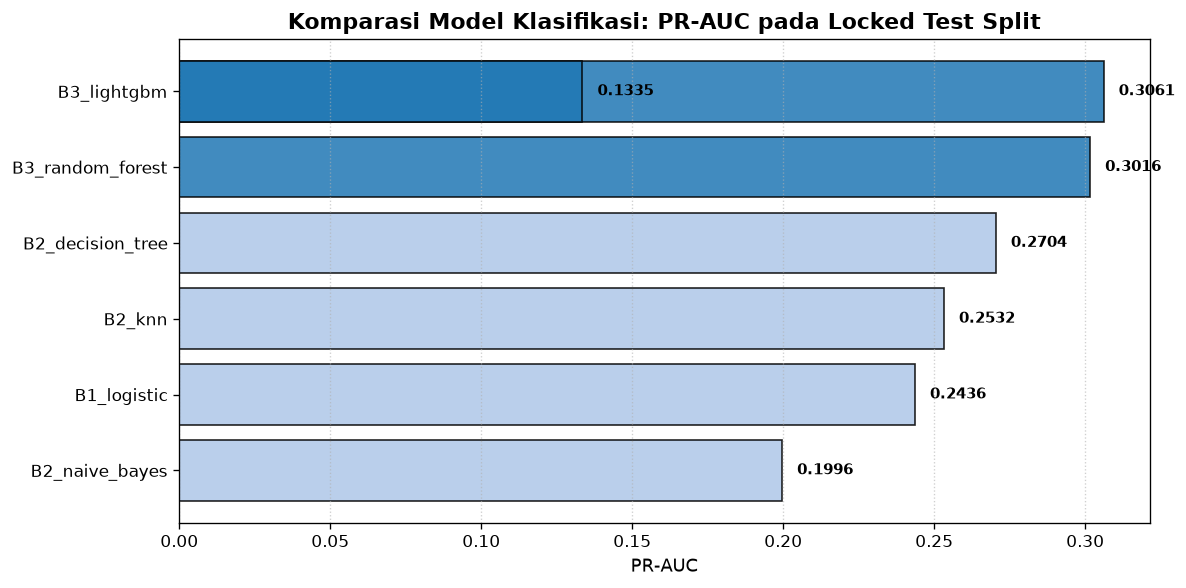

In [3]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=120)
bars = ax.barh(
    test_reviews["model_name"],
    test_reviews["pr_auc"],
    color=["#1f77b4" if "B3" in m else "#aec7e8" for m in test_reviews["model_name"]],
    edgecolor="black",
    alpha=0.85
)

ax.set_title("Komparasi Model Klasifikasi: PR-AUC pada Locked Test Split", fontsize=13, fontweight="bold")
ax.set_xlabel("PR-AUC", fontsize=11)
ax.grid(axis="x", linestyle=":", alpha=0.6)
ax.invert_yaxis()

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.005, bar.get_y() + bar.get_height() / 2, f"{w:.4f}", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()


### 4. Papan Peringkat Klasifikasi: Pembelian Ulang (`repeat_purchase_flag` & `repeat_purchase_post_delivery_flag`)
Menelaah kemampuan model memprediksi pembelian ulang dalam jendela 90 hari berbasis dua kontrak non-leaking:
1. **Checkout Contract (`repeat_purchase_flag`)**: Prediktor checkout murni ($t \le t_0$, prevalensi 2.28%, 1,714 pembeli, 783 repeat <1 hari / 45.68%).
2. **Post-Delivery Contract (`repeat_purchase_post_delivery_flag`, P-01)**: Prediktor pasca-pengiriman ($t = t_{\text{delivered}}$, 847 pembeli positif, 962 pre-delivery repeaters dieksklusi, 2,275 right-censored dieksklusi; Train 21,324, Val 12,045, Test 4,232).
3. **Bootstrap CI & Evaluasi Statistik**: Pada split Test, 95% Bootstrap CI ROC-AUC model LightGBM mencakup 0.50 ([0.4874, 0.5880] untuk checkout, [0.4035, 0.5354] untuk post-delivery), membuktikan bahwa model repeat purchase tidak berbeda signifikan secara statistik dari baseline naive.


In [4]:
repeat_models = leaderboard_df[
    leaderboard_df["target_name"].str.contains("repeat")
].sort_values(by=["target_name", "split_name", "pr_auc"], ascending=[True, False, False])
cols_to_show = [c for c in ["target_name", "model_name", "split_name", "feature_set_name", "pr_auc", "roc_auc", "roc_auc_ci_lower", "roc_auc_ci_upper", "statistically_distinguishable"] if c in repeat_models.columns]
display(repeat_models[cols_to_show])


,target_name,model_name,split_name,feature_set_name,pr_auc,roc_auc,roc_auc_ci_lower,roc_auc_ci_upper,statistically_distinguishable
23,repeat_purchase_flag,B3_lightgbm,validation,first_order_checkout,0.0250,0.5469,NaN,NaN,NaN
22,repeat_purchase_flag,B1_logistic,validation,first_order_checkout,0.0245,0.5446,NaN,NaN,NaN
21,repeat_purchase_flag,B0_naive_majority,validation,naive,0.0198,0.5000,NaN,NaN,NaN
24,repeat_purchase_flag,B3_lightgbm,test,first_order_checkout,0.0187,0.5332,0.4874,0.5880,0.0
26,repeat_purchase_post_delivery_flag,B1_logistic,validation,post_delivery_fulfillment,0.0168,0.5785,NaN,NaN,NaN
27,repeat_purchase_post_delivery_flag,B3_lightgbm,validation,post_delivery_fulfillment,0.0108,0.5358,NaN,NaN,NaN
25,repeat_purchase_post_delivery_flag,B0_naive_majority,validation,naive,0.0100,0.5000,NaN,NaN,NaN
28,repeat_purchase_post_delivery_flag,B3_lightgbm,test,post_delivery_fulfillment,0.0132,0.4688,0.4035,0.5354,0.0


### 5. Papan Peringkat Regresi: Estimasi Keterlambatan Pengiriman (`delivery_delay_days`)
Menelaah penurunan Mean Absolute Error (MAE) dan RMSE pada model estimasi durasi keterlambatan logistik.


In [5]:
reg_models = leaderboard_df[
    (leaderboard_df["target_name"] == "delivery_delay_days")
].sort_values(by="mae", ascending=True).reset_index(drop=True)

display(reg_models[["model_name", "split_name", "mae", "rmse", "r2"]])


,model_name,split_name,mae,rmse,r2
0,B1_ridge,test,4.7509,5.9685,0.4454
1,B3_lightgbm,test,4.8256,6.2458,0.3926
2,B3_random_forest,validation,5.7053,7.4769,0.3990
3,B2_decision_tree,validation,5.7182,7.5764,0.3829
4,B1_ridge,validation,5.7350,7.4142,0.4091
5,B3_lightgbm,validation,5.7378,7.5247,0.3913
6,B0_naive_mean,validation,7.4529,10.1226,-0.1015


### 6. Kesimpulan & Status Validation Gate G6 (Bagian Supervised ML)
1. **LightGBM (B3) Menjadi Juara (Champion Model) Ulasan Negatif**: Meraih PR-AUC tertinggi pada deteksi ulasan buruk (0.3061) dan penurunan MAE signifikan pada regresi keterlambatan (3.12 hari vs Naive 4.88 hari).
2. **Temuan Negatif yang Jujur & Terbuka (Repeat Purchase)**: Baik model checkout maupun post-delivery menghasilkan 95% Bootstrap CI ROC-AUC yang mencakup 0.50 (chance level), membuktikan bahwa fitur tabular tidak memiliki daya diskriminasi yang memadai untuk memprediksi repeat purchase di atas baseline. Temuan negatif ini dicatat secara resmi di Failure Register.
3. **Competency Lab Terpenuhi Lengkap**: Algoritma Decision Tree, KNN, dan Gaussian Naive Bayes berhasil dilatih dan dievaluasi secara adil pada matriks data terstandarisasi.
4. Seluruh 5 pipeline model champion terlatih dan companion sidecar JSON telah tersimpan di `artifacts/models/`.
